# Sistem Rekomendasi: Content-Based Filtering

**Content-Based Filtering** merekomendasikan item berdasarkan kemiripan fitur kontennya dengan item yang disukai pengguna sebelumnya.

---

### 1. Pembobotan Kata (TF-IDF)

Mengubah teks fitur menjadi vektor angka dengan memberi bobot tinggi pada kata yang unik di suatu dokumen:
$$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \log\left(\frac{N}{\text{DF}(t)}\right)$$

- **Fungsi Tiap Simbol:**
  - $t$ (_Term_): Kata tertentu yang sedang dihitung bobotnya.
  - $d$ (_Document_): Satu dokumen atau deskripsi item tertentu.
  - $\text{TF}(t, d)$: Frekuensi kemunculan kata $t$ dibagi total kata dalam dokumen $d$.
  - $N$: Jumlah total seluruh dokumen dalam dataset.
  - $\text{DF}(t)$: Jumlah dokumen yang mengandung kata $t$.
  - $\log$: Logaritma untuk mengecilkan bobot kata yang terlalu umum muncul di banyak dokumen.
- **Contoh Sederhana:**
  Kata `"petir"` muncul **1 kali** dari **4 kata** pada film _Gundala_ ($\text{TF} = 0.25$), dan hanya ada di **1 film** dari total **6 film** ($\text{IDF} = \log(6/1) \approx 0.778$). Bobotnya adalah $0.25 \times 0.778 = \mathbf{0.1945}$.

---

### 2. Kemiripan Vektor (Cosine Similarity)

Mengukur tingkat kemiripan antara dua vektor item ($A$ dan $B$) berdasarkan sudut kosinus di antara keduanya (rentang nilai `0.0` hingga `1.0`):
$$\text{Cosine Similarity}(A, B) = \frac{A \cdot B}{\|A\| \|B\|} = \frac{\sum_{i=1}^{n} A_i B_i}{\sqrt{\sum_{i=1}^{n} A_i^2} \sqrt{\sum_{i=1}^{n} B_i^2}}$$

- **Fungsi Tiap Simbol:**
  - $A, B$: Dua vektor angka yang merepresentasikan fitur dua item berbeda.
  - $A \cdot B$: Perkalian titik (_dot product_) antara elemen berpasangan vektor $A$ dan $B$.
  - $\|A\|, \|B\|$: Panjang geometris (_Euclidean norm_) dari vektor $A$ dan $B$.
  - $n$: Jumlah total dimensi (jumlah kata unik dalam kosakata).
  - $i$: Indeks urutan posisi elemen di dalam vektor (dari $1$ sampai $n$).
  - $A_i, B_i$: Nilai bobot TF-IDF pada posisi fitur ke-$i$ untuk masing-masing vektor.
  - $\sum_{i=1}^{n}$: Penjumlahan beruntun dari elemen ke-$1$ hingga ke-$n$.
  - $\sqrt{\dots}$: Akar kuadrat untuk menghitung panjang vektor.
- **Contoh Sederhana:**
  Misalkan vektor fitur dua film adalah $A = [1, 0]$ dan $B = [1, 1]$.
  1. **Perkalian Titik ($A \cdot B$)**: $(1 \times 1) + (0 \times 1) = 1$
  2. **Panjang Vektor**: $\|A\| = \sqrt{1^2 + 0^2} = 1$, dan $\|B\| = \sqrt{1^2 + 1^2} \approx 1.414$
  3. **Hasil**: $\frac{1}{1 \times 1.414} \approx \mathbf{0.707}$ (Tingkat kemiripan **70.7%**)

---

### 3. Kelebihan & Kekurangan

#### Kelebihan (Pros)

- **Independen terhadap Pengguna Lain:** Tidak memerlukan data interaksi atau _rating_ dari pengguna lain untuk membuat rekomendasi.
- **Mengatasi _Cold-Start_ Item Baru:** Item baru dapat langsung direkomendasikan selama deskripsi atau fiturnya tersedia.
- **Transparan & Mudah Dijelaskan:** Alasan rekomendasi sangat jelas karena didasarkan pada kemiripan fitur spesifik (misalnya kesamaan genre atau kata kunci).

#### Kekurangan (Cons)

- **Terjebak dalam _Filter Bubble_:** Sistem cenderung hanya merekomendasikan item yang sangat mirip dengan riwayat sebelumnya, sehingga membatasi eksplorasi minat baru (_overspecialization_).
- **Bergantung pada Kualitas Fitur:** Akurasi menurun drastis jika metadata atau deskripsi konten tidak lengkap, tidak konsisten, atau sulit diekstrak.
- **Masalah _Cold-Start_ Pengguna Baru:** Tidak dapat memberikan rekomendasi yang dipersonalisasi kepada pengguna baru yang belum memiliki riwayat interaksi sama sekali.


In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
def computeSimilarity(dataFrame: pd.DataFrame) -> np.ndarray:
  '''
  Mengubah teks fitur menjadi vektor TF-IDF dan menghitung matriks Cosine Similarity.

  Args:
    dataFrame (pd.DataFrame): Tabel data yang memiliki kolom features.

  Returns:
    np.ndarray: Matriks persegi berisi skor kemiripan (0.0 hingga 1.0).
  '''
  # Variabel lokal disusun secara alfabetis
  similarityMatrix = np.array([])
  tfidfMatrix = None
  vectorizer = TfidfVectorizer()

  # Ekstraksi fitur teks menjadi matriks TF-IDF
  tfidfMatrix = vectorizer.fit_transform(dataFrame['features'])

  # Komputasi skor kemiripan kosinus antar semua dokumen
  similarityMatrix = cosine_similarity(tfidfMatrix, tfidfMatrix)
  return similarityMatrix

def createDataset() -> pd.DataFrame:
  '''
  Membuat dataset contoh berisi daftar film dan kata kunci genrenya.

  Returns:
    pd.DataFrame: Tabel berisi kolom features dan title.
  '''
  movieData = {
    'features': [
      'action martial arts crime silat',
      'drama family education inspirational',
      'comedy family friendship office',
      'action superhero lightning fantasy',
      'comedy drama family store',
      'action martial arts crime mystery',
    ],
    'title': [
      'The Raid',
      'Laskar Pelangi',
      'Warkop DKI Reborn',
      'Gundala',
      'Cek Toko Sebelah',
      'Headshot',
    ],
  }
  return pd.DataFrame(movieData)

def getRecommendations(
  dataFrame: pd.DataFrame,
  referenceTitle: str,
  similarityMatrix: np.ndarray,
  topN: int,
) -> pd.DataFrame:
  '''
  Mengambil daftar item teratas yang paling mirip dengan item acuan.

  Args:
    dataFrame (pd.DataFrame): Tabel data sumber.
    referenceTitle (str): Judul item yang dijadikan referensi.
    similarityMatrix (np.ndarray): Matriks skor kemiripan antar item.
    topN (int): Banyaknya rekomendasi yang diinginkan.

  Returns:
    pd.DataFrame: Tabel berisi item rekomendasi beserta skor kemiripannya.
  '''
  # Variabel lokal disusun secara alfabetis
  referenceIndex = dataFrame[dataFrame['title'] == referenceTitle].index[0]
  resultFrame = pd.DataFrame()
  rowScores = similarityMatrix[referenceIndex]
  scorePairs = []
  topIndices = []
  topScores = []

  # Mengurutkan pasangan (indeks, skor) dari nilai tertinggi ke terendah
  scorePairs = sorted(
    list(enumerate(rowScores)),
    key=lambda item: item[1],
    reverse=True,
  )

  # Mengambil urutan ke-1 dst. untuk melewati item acuan itu sendiri (indeks ke-0)
  topIndices = [item[0] for item in scorePairs[1 : topN + 1]]
  topScores = [round(item[1], 4) for item in scorePairs[1 : topN + 1]]

  resultFrame = dataFrame.iloc[topIndices].copy()
  resultFrame['similarityScore'] = topScores
  return resultFrame

def plotResults(
  dataFrame: pd.DataFrame,
  recommendationFrame: pd.DataFrame,
  referenceTitle: str,
  similarityMatrix: np.ndarray,
) -> None:
  '''
  Menampilkan visualisasi heatmap matriks kemiripan dan grafik batang rekomendasi.

  Args:
    dataFrame (pd.DataFrame): Tabel data sumber lengkap.
    recommendationFrame (pd.DataFrame): Tabel hasil rekomendasi teratas.
    referenceTitle (str): Judul item yang dijadikan referensi.
    similarityMatrix (np.ndarray): Matriks skor kemiripan antar item.
  '''
  # Variabel lokal disusun secara alfabetis
  axes = None
  figure = None
  titles = dataFrame['title'].tolist()

  figure, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Plot 1: Heatmap kemiripan seluruh film pada subplot pertama (axes[0])
  sns.heatmap(
    similarityMatrix,
    annot=True,
    ax=axes[0],
    cmap='YlGnBu',
    fmt='.2f',
    xticklabels=titles,
    yticklabels=titles,
  )
  axes[0].set_title('Cosine Similarity Matrix', pad=12)
  axes[0].tick_params(axis='x', rotation=35)

  # Plot 2: Diagram batang skor rekomendasi teratas pada subplot kedua (axes[1])
  sns.barplot(
    ax=axes[1],
    data=recommendationFrame,
    hue='title',
    legend=False,
    palette='viridis',
    x='similarityScore',
    y='title',
  )
  axes[1].set_xlim(0, 1.05)
  axes[1].set_xlabel('Similarity Score (0.0 - 1.0)')
  axes[1].set_ylabel('Movie Title')
  axes[1].set_title(f"Top Recommendations Similar to '{referenceTitle}'", pad=12)

  # Menambahkan label angka tepat di ujung setiap batang
  for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.4f', padding=4)

  plt.tight_layout()
  plt.show()

,features,title,similarityScore
5,action martial arts crime mystery,Headshot,0.7140
3,action superhero lightning fantasy,Gundala,0.1374
1,drama family education inspirational,Laskar Pelangi,0.0000


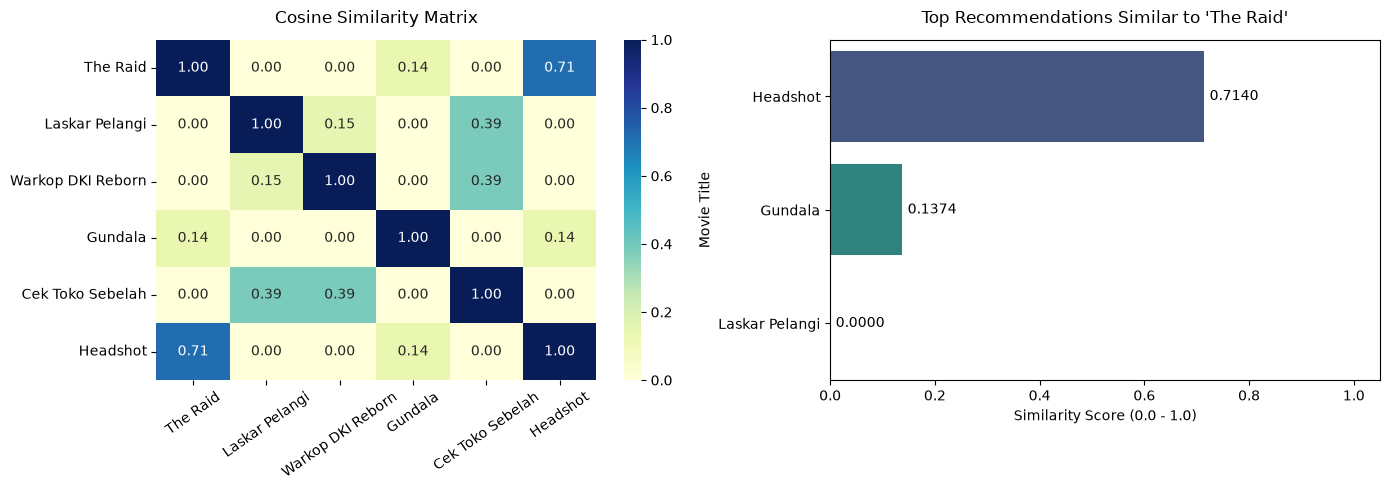

In [3]:
# Variabel utama disusun secara alfabetis
movieFrame = createDataset()
recommendationFrame = pd.DataFrame()
similarityMatrix = computeSimilarity(dataFrame=movieFrame)
targetTitle = 'The Raid'

# Menghitung 3 rekomendasi teratas untuk 'The Raid'
recommendationFrame = getRecommendations(
  dataFrame=movieFrame,
  referenceTitle=targetTitle,
  similarityMatrix=similarityMatrix,
  topN=3,
)

# Menampilkan tabel hasil dan visualisasi grafik
display(recommendationFrame)
plotResults(
  dataFrame=movieFrame,
  recommendationFrame=recommendationFrame,
  referenceTitle=targetTitle,
  similarityMatrix=similarityMatrix,
)